# Лабораторная работа 4 Кластеризация
К. Р. Халикова, группа 4417.

## Цель работы
Изучение алгоритмов и методов кластеризации на практике.

## Вариант 1
Был использован набор `medical_diagnosis.csv`. В первой части исследованы синтетические двумерные данные, во второй выполнена кластеризация медицинских наблюдений методами K-means и Ward. Исходный класс `Disease` исключён из признаков модели.

Кластеризация объединяет объекты в группы по сходству их признаков без передачи правильных меток при обучении. Номер кластера является условным обозначением группы, а не названием исходного класса.

## 1 Кластеризация синтетических данных
Для генерации использована функция `make_data` из методических указаний без изменения алгоритма. Выбраны `n = 100` объектов в каждой из трёх групп и `seed = 21`; всего получено 300 наблюдений с признаками `x` и `y`. Оба столбца являются входными признаками. Значение `seed` фиксирует случайные данные, но не обозначает номер варианта.

Разброс `x` и `y` различается из-за множителей 20 и 0,5. Поэтому перед кластеризацией выполняется стандартизация: `StandardScaler` вычитает среднее и делит каждый признак на его стандартное отклонение. Это делает масштабы признаков сопоставимыми при вычислении расстояний. Все модели первой части обучаются на стандартизованных данных, а координаты центров для рисунков переводятся обратно в исходные единицы через `inverse_transform`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display # показать данные
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def make_data(n, seed):
    np.random.seed(seed)
    shift_matrix = np.array([[3, 3], [6, 9], [9, 3]])
    data = np.random.randn(3, 2, n) + shift_matrix.reshape((3, 2, 1))
    data = np.swapaxes(data, 1, 2)
    data = data.reshape((-1, 2))
    data *= np.array([[20, 0.5]])
    df = pd.DataFrame({'x': data[:, 0], 'y': data[:, 1]},
                      columns=['x', 'y'])
    df = df.sample(frac=1.0)
    return df

df = make_data(100, 21)
display(df.head())
print('Количество объектов:', len(df))
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

Количество объектов: 300


,x,y
236,195.766368,1.362341
260,155.199288,0.749502
251,194.170649,1.131834
246,199.602012,2.807162
174,108.301062,4.583723


### Кластеризация при k = 3, 2, 4
K-means назначает объекты ближайшим центрам, затем пересчитывает центры как средние значения признаков внутри групп. Шаги повторяются до выполнения условия остановки. Для каждого числа кластеров применяется `fit_predict`: модель обучается и возвращает метки тех объектов, на которых выполнено обучение.

Расчёт сначала выполняется для трёх кластеров, затем повторяется для двух и четырёх. `n_init = 10` задаёт десять инициализаций; из них выбирается результат с минимальной суммой квадратов расстояний до центров. `random_state = 21` обеспечивает воспроизводимость инициализаций. 
На следующих трёх графиках по горизонтали показан `x`, по вертикали `y`. Каждая точка является искусственным объектом, её цвет соответствует найденному кластеру. Красные кресты обозначают центры обученной модели в исходных единицах. Цвета разных графиков назначаются независимо, поэтому одинаковый цвет сам по себе не означает одну и ту же группу между моделями.

Для сравнения разбиений рассчитывается средний коэффициент силуэта в стандартизованном пространстве. Он сопоставляет среднее расстояние до объектов своей группы со средним расстоянием до ближайшей другой группы. Большее значение обычно означает лучшее геометрическое разделение. В отчёте график при `k = 3` соответствует рисунку 1, а графики при `k = 2` и `k = 4` объединены в рисунок 2; значения силуэта приведены в таблице 1.

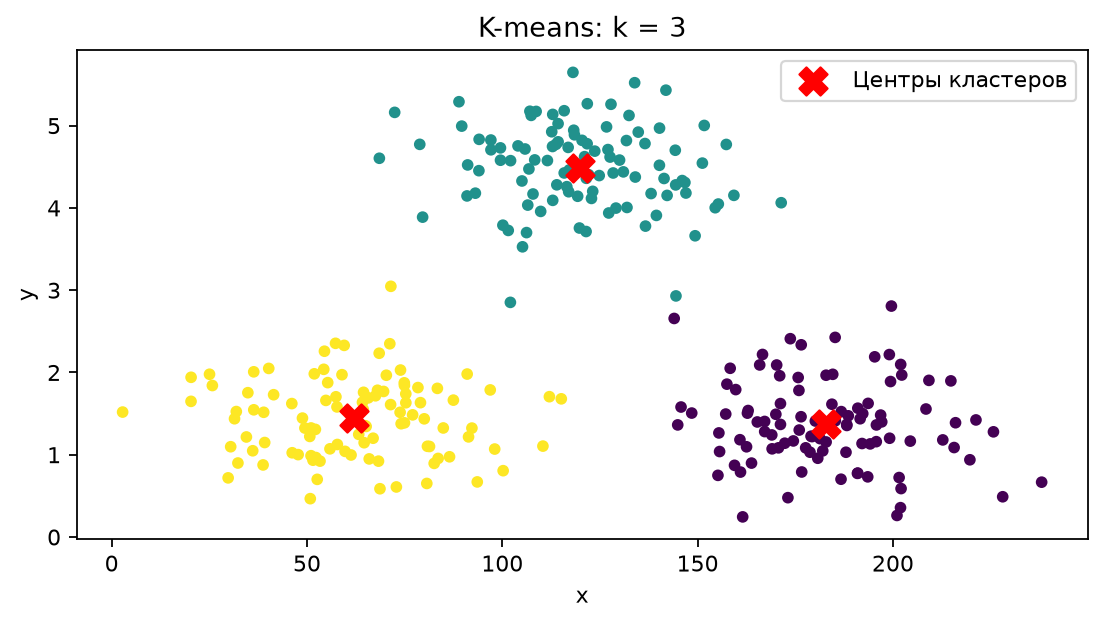

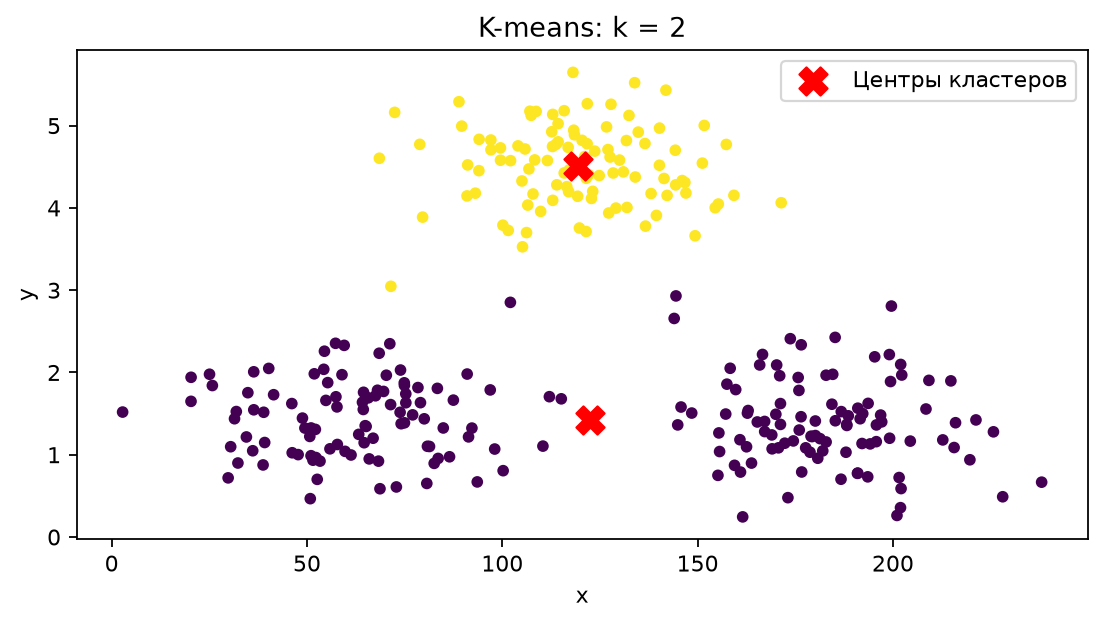

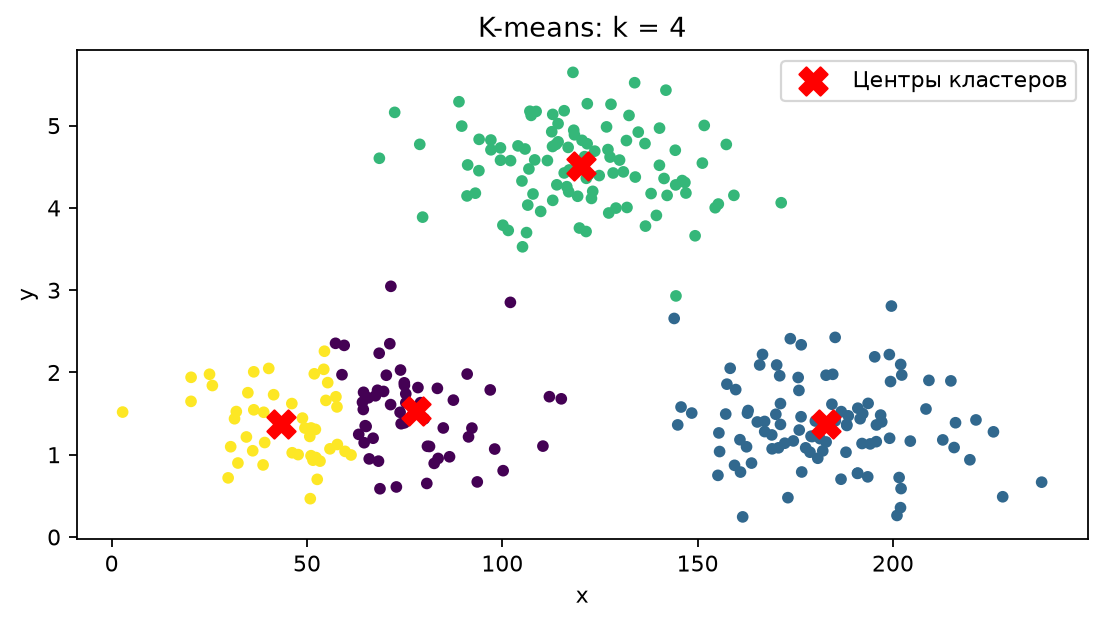

,silhouette
k,
3,0.703422
2,0.488711
4,0.573960


In [2]:
part1_rows = []
part1_models = {}
for k in [3, 2, 4]:
    model = KMeans(n_clusters=k, n_init=10, random_state=21)
    labels = model.fit_predict(X_scaled)
    part1_models[k] = model
    part1_rows.append({'k': k, 'silhouette': silhouette_score(X_scaled, labels)})
    centers = scaler.inverse_transform(model.cluster_centers_)
    plt.figure(figsize=(7, 4))
    plt.scatter(df.x, df.y, c=labels, cmap='viridis', s=18)
    plt.scatter(centers[:, 0], centers[:, 1], c='red',
                marker='X', s=160, label='Центры кластеров')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(f'K-means: k = {k}')
    plt.legend()
    plt.tight_layout()
    plt.show()
part1_metrics = pd.DataFrame(part1_rows).set_index('k')
display(part1_metrics)

### Результаты сравнения числа кластеров
При `k = 3` получен силуэт 0,7034, при `k = 2` - 0,4887, при `k = 4` - 0,5740. Наибольшее значение соответствует трём кластерам и согласуется с тремя группами, заданными функцией генерации. При двух кластерах две нижние исходные группы объединяются, при четырёх одна из исходных групп дробится. Поэтому для данного синтетического набора среди проверенных разбиений предпочтительно `k = 3`.

### Метод локтя
Для `k` от 1 до 9 рассчитывается `inertia_`, сумма квадратов расстояний до центров в стандартизованном пространстве. На следующем графике по горизонтали показано число кластеров, по вертикали эта сумма. Каждая точка соответствует отдельно обученной модели, а линия соединяет значения критерия. Она не является линией регрессии или графиком времени обучения.

Метод локтя ищет перегиб, после которого дальнейшее увеличение числа групп уменьшает разброс заметно слабее. Минимум `inertia_` по всем `k` сам по себе не определяет полезное число кластеров: дополнительное дробление обычно уменьшает этот критерий. График соответствует рисунку 3 отчёта.

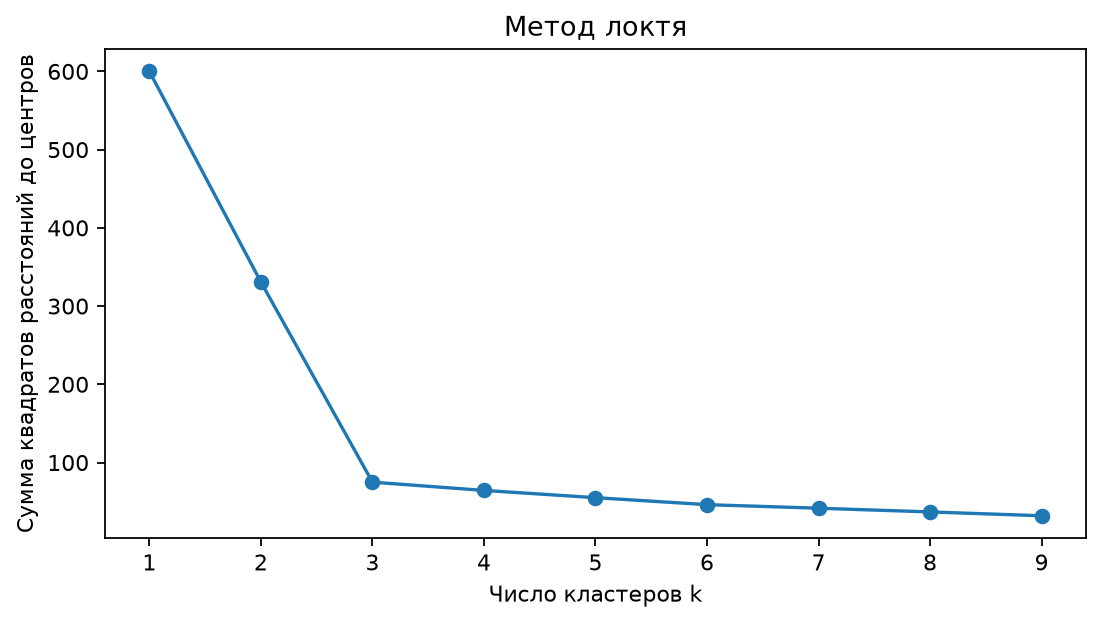

In [3]:
inertia = []
for k in range(1, 10):
    model = KMeans(n_clusters=k, n_init=10, random_state=21)
    model.fit(X_scaled)
    inertia.append(model.inertia_)
plt.figure(figsize=(7, 4))
plt.plot(range(1, 10), inertia, marker='o')
plt.xlabel('Число кластеров k')
plt.ylabel('Сумма квадратов расстояний до центров')
plt.title('Метод локтя')
plt.xticks(range(1, 10))
plt.tight_layout()
plt.show()

### Вывод по 1 части
На кривой `inertia_` основной перегиб соответствует `k = 3`: после этого значения уменьшаются значительно медленнее. Этот результат согласуется с максимальным силуэтом среди `k = 2, 3, 4` и заданной структурой генератора.



## 2 Подготовка медицинских данных Вариант 1
Исходный файл `medical_diagnosis.csv` содержит 3031 строку и 14 столбцов: возраст `age`, пол `sex`, индекс массы тела `BMI`, систолическое давление `systolic_bp`, холестерин `cholesterol_mg_dl`, глюкозу натощак `fasting_glucose_mg_dl`, статус курения `smoking_status`, наследственность `family_history`, активность `activity_level`, выраженность симптомов `symptom_score`, С-реактивный белок `CRP_mg_L`, число лейкоцитов `WBC_10e9_L`, результат ЭКГ `ECG_result` и класс `Disease`. По исходной разметке `Disease = 1` означает заболевание, `Disease = 0` его отсутствие.

### Загрузка и предварительная обработка
Проверяются типы столбцов, пропуски, полные дубликаты и описательные статистики. Повторные полные строки удаляются. Заполнение пропусков не применяется, поскольку пропусков нет. Высокие лабораторные показатели сохраняются: без подтверждения ошибки измерения статистическая необычность не является основанием для удаления. Их влияние учитывается при интерпретации групп.

In [4]:
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score
from sklearn.metrics import homogeneity_score, completeness_score
from scipy.cluster.hierarchy import linkage, dendrogram

medical = pd.read_csv('medical_diagnosis.csv')
print('Размер исходных данных:', medical.shape)
medical.info()
print('Пропуски:', medical.isna().sum().sum())
print('Полные дубликаты:', medical.duplicated().sum())
medical = medical.drop_duplicates().copy()
print('Размер после удаления дубликатов:', medical.shape)
display(medical.describe().round(3))
print('Количество объектов классов:')
display(medical['Disease'].value_counts().sort_index())

Размер исходных данных: (3031, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3031 entries, 0 to 3030
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   age                    3031 non-null   int64  
 1   sex                    3031 non-null   object 
 2   BMI                    3031 non-null   float64
 3   systolic_bp            3031 non-null   float64
 4   cholesterol_mg_dl      3031 non-null   float64
 5   fasting_glucose_mg_dl  3031 non-null   float64
 6   smoking_status         3031 non-null   object 
 7   family_history         3031 non-null   object 
 8   activity_level         3031 non-null   object 
 9   symptom_score          3031 non-null   float64
 10  CRP_mg_L               3031 non-null   float64
 11  WBC_10e9_L             3031 non-null   float64
 12  ECG_result             3031 non-null   object 
 13  Disease                3031 non-null   int64  
dtypes: float64(7), int64(

,age,BMI,systolic_bp,cholesterol_mg_dl,fasting_glucose_mg_dl,symptom_score,CRP_mg_L,WBC_10e9_L,Disease
count,3030.000,3030.000,3030.000,3030.000,3030.000,3030.000,3030.000,3030.000,3030.000
mean,53.178,26.466,122.414,202.667,94.367,2.040,1.373,6.823,0.016
std,20.743,5.871,17.862,53.573,19.550,1.358,3.131,1.978,0.126
min,18.000,13.500,82.000,85.000,56.000,0.000,0.100,2.300,0.000
25%,35.000,22.500,110.000,171.000,80.250,1.000,0.100,5.480,0.000
50%,53.000,26.300,122.000,200.000,94.000,2.000,0.520,6.750,0.000
75%,71.000,30.400,134.000,232.000,107.000,3.000,1.460,8.150,0.000
max,89.000,50.900,184.000,658.200,163.000,6.800,43.450,13.720,1.000


Disease
0    2981
1      49
Name: count, dtype: int64

### Результат предварительной обработки
Пропусков не обнаружено. Найден и удалён один полный дубликат; осталось 3030 наблюдений. Из них 49 имеют `Disease = 1` и 2981 имеют `Disease = 0`. Поэтому исходные классы сильно несбалансированы, что необходимо учитывать при интерпретации согласия кластеров с разметкой.

### Выделение целевого класса и матрица диаграмм
`Disease` используется только для окраски исходных наблюдений и внешних метрик после обучения. Он не участвует в обучении или выборе числа кластеров. В `X` оставлены восемь числовых признаков. Пять категориальных столбцов `sex`, `smoking_status`, `family_history`, `activity_level`, `ECG_result` не включены: их кодирование выделено в методичке в дополнительные задания.

Единицы числовых признаков соответствуют таблице 2 отчёта:

| Признак | Смысл и единицы |
| --- | --- |
| `age` | Возраст, лет |
| `BMI` | Индекс массы тела, кг/м² |
| `systolic_bp` | Систолическое давление, мм рт. ст. |
| `cholesterol_mg_dl` | Холестерин, мг/дл |
| `fasting_glucose_mg_dl` | Глюкоза натощак, мг/дл |
| `symptom_score` | Выраженность симптомов, шкала 0-10 |
| `CRP_mg_L` | С-реактивный белок, мг/л |
| `WBC_10e9_L` | Лейкоциты, 10⁹/л |

Матрица диаграмм строится до стандартизации в исходных единицах. Каждый столбец матрицы задаёт горизонтальный признак, каждая строка вертикальный. На диагонали показаны гистограммы одного признака, вне диагонали пары признаков. Каждая точка соответствует наблюдению после удаления дубликата; цвет обозначает исходный `Disease`, а не кластер модели. Краткие подписи сохраняют порядок восьми признаков. Этот график соответствует рисунку 4 отчёта.

После построения матрицы выполняется стандартизация всех восьми столбцов для обучения моделей. Состав и порядок строк при этом сохраняются.
StandardScaler вычитает среднее и делит на стандартное отклонение каждого признака, рассчитанные по всем подготовленным объектам этой работы.

Признаки модели: ['age', 'BMI', 'systolic_bp', 'cholesterol_mg_dl', 'fasting_glucose_mg_dl', 'symptom_score', 'CRP_mg_L', 'WBC_10e9_L']


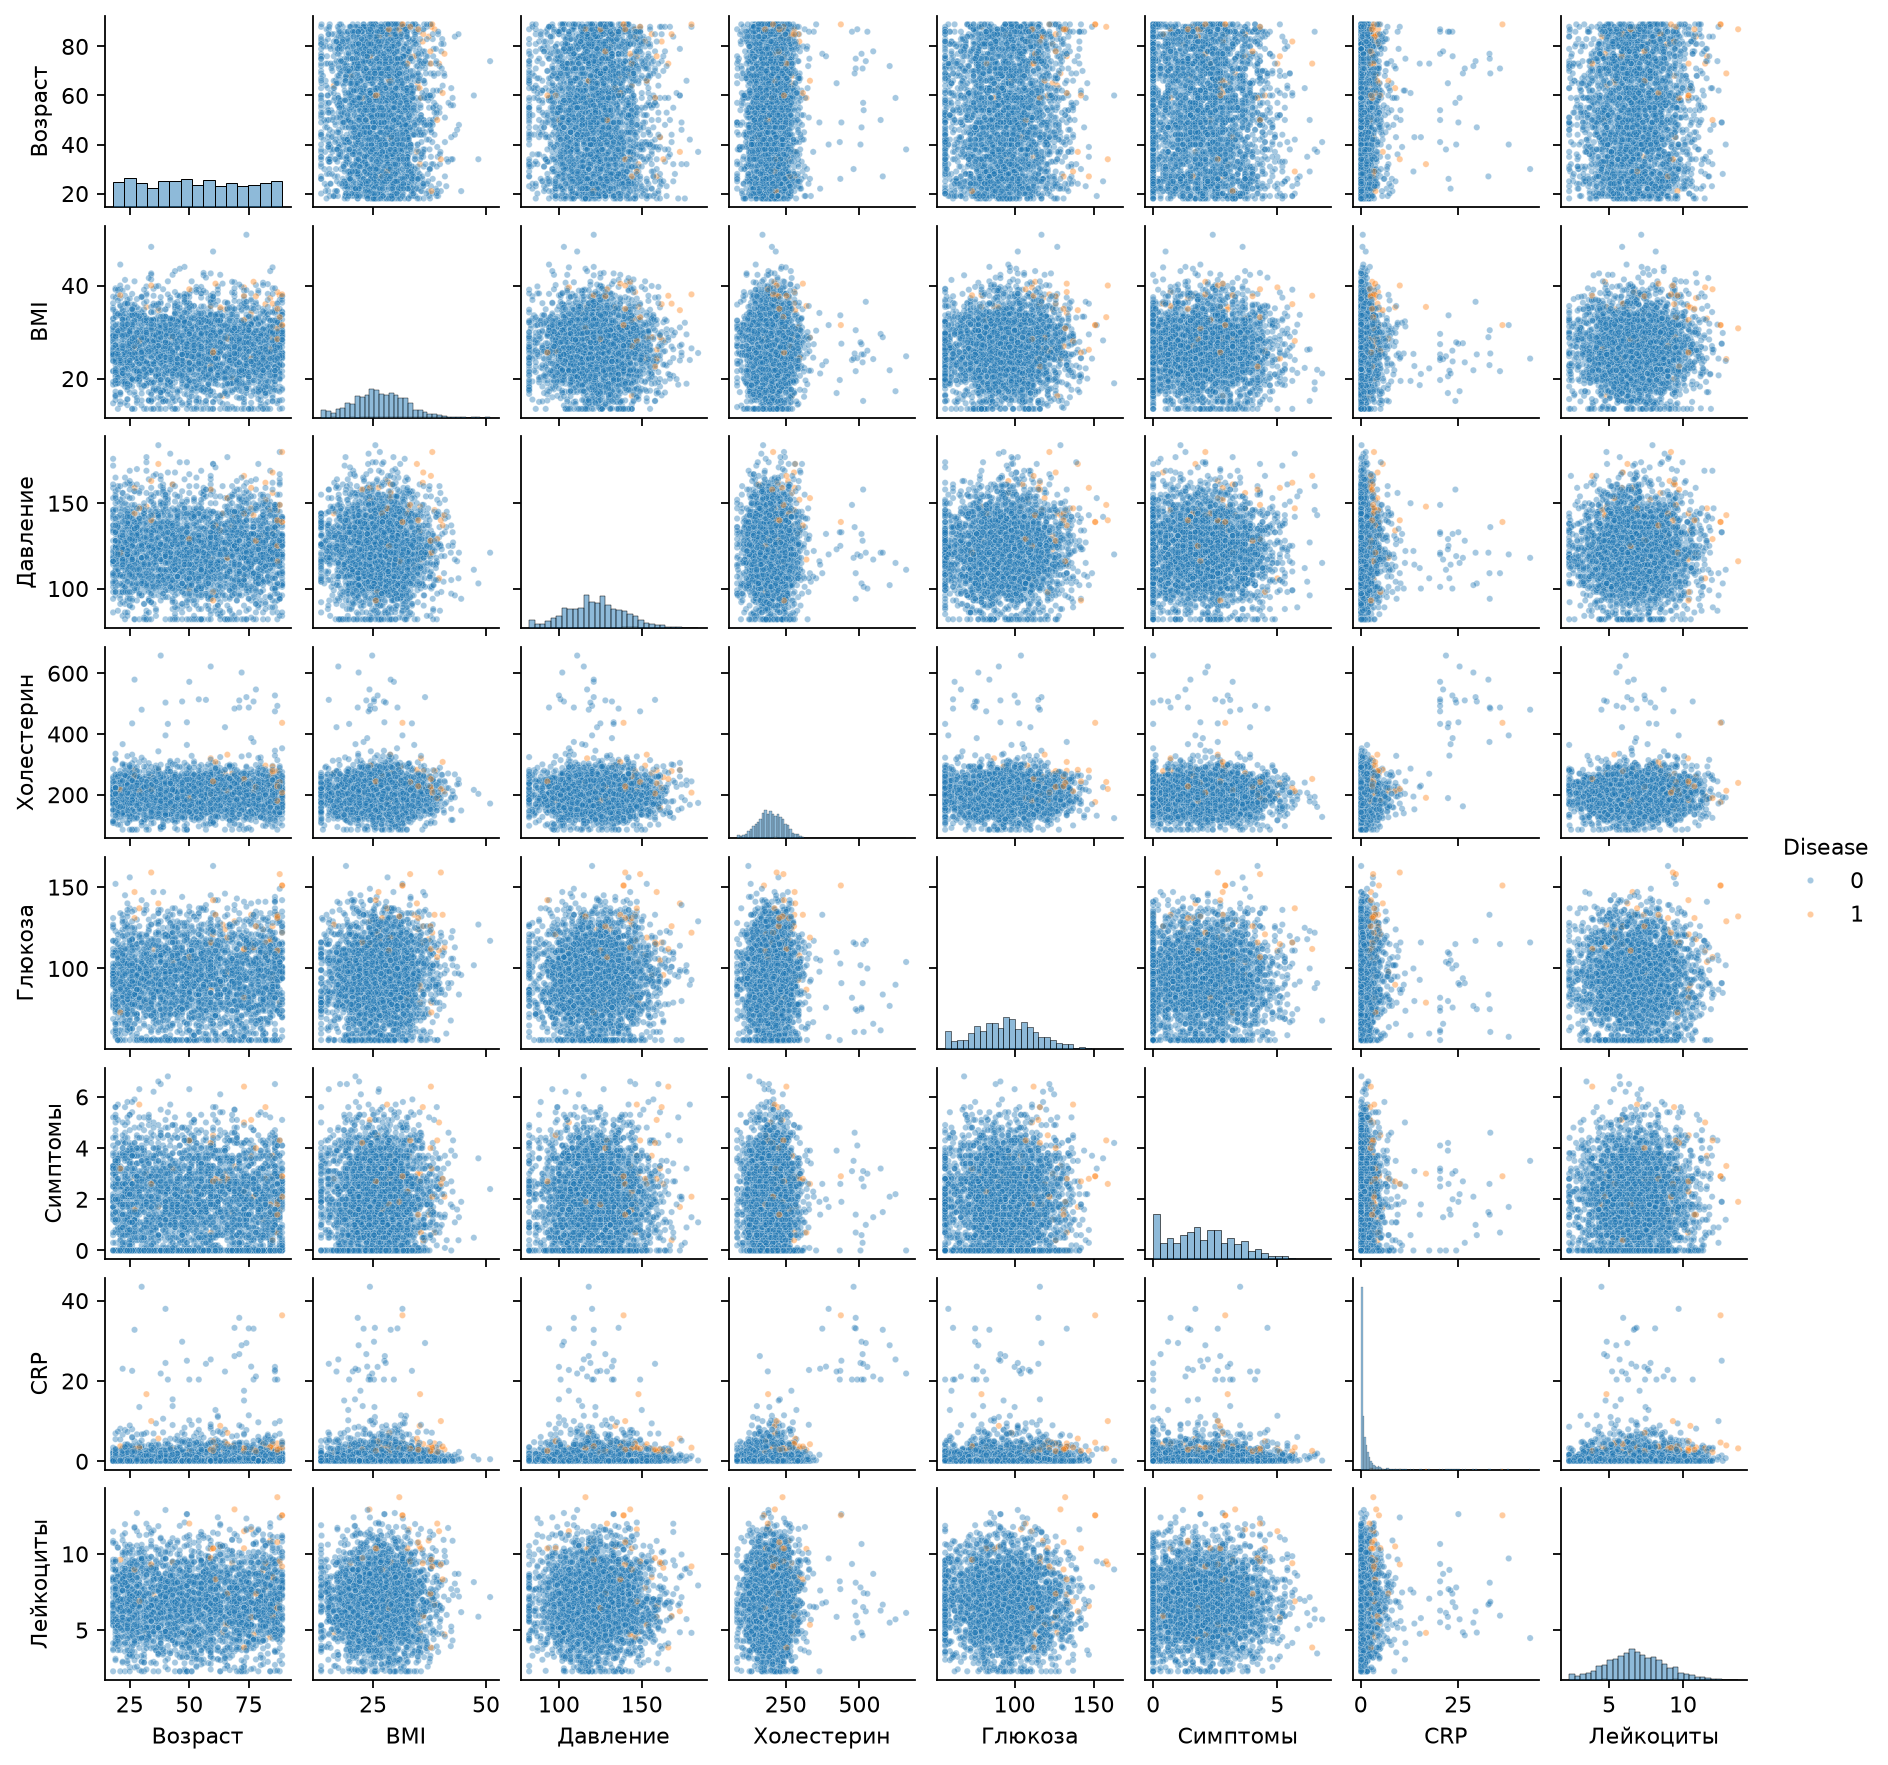

In [5]:
y_true = medical['Disease']
X = medical.drop(columns='Disease').select_dtypes(include='number')
print('Признаки модели:', X.columns.tolist())
pair_data = X.rename(columns={
    'age': 'Возраст', 'systolic_bp': 'Давление',
    'cholesterol_mg_dl': 'Холестерин',
    'fasting_glucose_mg_dl': 'Глюкоза', 'symptom_score': 'Симптомы',
    'CRP_mg_L': 'CRP', 'WBC_10e9_L': 'Лейкоциты'})
pair_data['Disease'] = y_true
sns.pairplot(pair_data, hue='Disease', diag_kind='hist',
             plot_kws={'s': 8, 'alpha': 0.4}, height=1.4)
plt.show()
scaler_medical = StandardScaler()
X_medical_scaled = scaler_medical.fit_transform(X)

### Наблюдения по матрице диаграмм
Цвета исходных классов не демонстрируют чёткого разделения в показанных парах признаков. Заметна небольшая группа высоких значений CRP и холестерина. Положительных случаев мало, что согласуется с дисбалансом `Disease`.
Матрица описывает исходные признаки до кластеризации; это не результат обучения K-means или Ward. Двумерные проекции полезны для предварительного изучения, но не дают окончательной оценки разделения в восьмимерном пространстве. Модели далее получают стандартизованные признаки.

### K-means и выбор числа кластеров
Сравниваются `k` от 2 до 9 по среднему силуэту в стандартизованном пространстве. Для каждого `k` использованы 10 инициализаций и `random_state = 21`. Выбирается `k` с максимальным силуэтом; `inertia_` используется как дополнительный графический ориентир. `Disease` при выборе не используется.

Кластеризация выполняется на всех 3030 подготовленных объектах. В порядке выполнения методички на страницах 18 и 23 этап разделения на `train` и `test` не предусмотрен. Здесь исследуется структура имеющегося набора, а не качество предсказаний для новых пациентов. Это постановка данной работы, а не общий запрет на разделение данных при кластеризации. Значения метрик относятся к исследованному набору.

Выводимая таблица содержит критерии для каждого числа групп и соответствует таблице 3 отчёта. На следующем рисунке по горизонтали в обеих панелях показано `k`, слева по вертикали `inertia`, справа средний силуэт. Каждая точка соответствует результату K-means для данного `k` на одних и тех же восьми стандартизованных признаках. Графики соответствуют рисунку 5 отчёта.

Выбранное число кластеров: 2


,inertia,silhouette
k,,
2,21918.0580,0.1068
3,20511.6964,0.0907
4,17741.1248,0.1003
5,16628.4537,0.1007
6,15740.0508,0.1007
7,15001.0696,0.1015
8,14434.8283,0.1025
9,13990.3717,0.1023


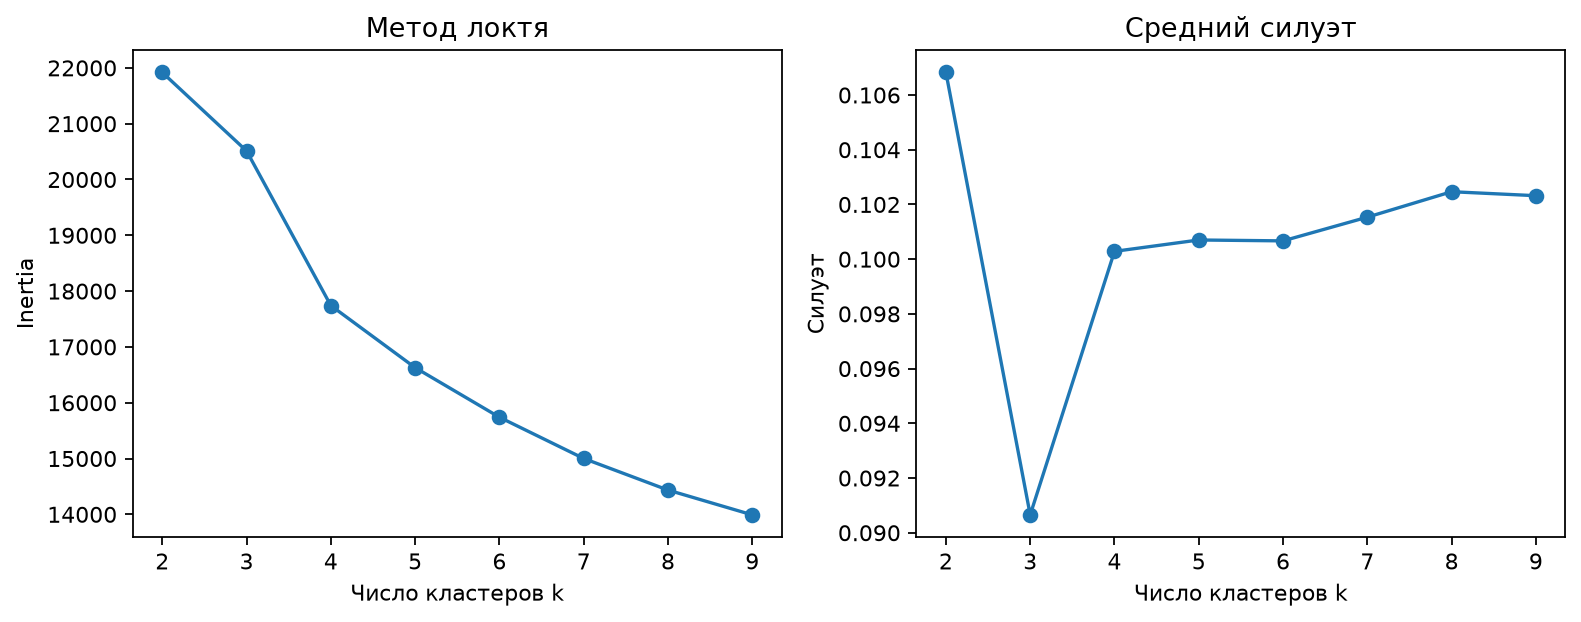

In [6]:
selection_rows = []
medical_models = {}
for k in range(2, 10):
    model = KMeans(n_clusters=k, n_init=10, random_state=21)
    labels = model.fit_predict(X_medical_scaled)
    medical_models[k] = model
    selection_rows.append({'k': k, 'inertia': model.inertia_,
                           'silhouette': silhouette_score(X_medical_scaled, labels)})
selection = pd.DataFrame(selection_rows).set_index('k')
display(selection.round(4))
best_k = int(selection['silhouette'].idxmax())
kmeans_medical = medical_models[best_k]
labels_kmeans = kmeans_medical.labels_
print('Выбранное число кластеров:', best_k)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(selection.index, selection.inertia, marker='o')
axes[0].set(xlabel='Число кластеров k', ylabel='Inertia', title='Метод локтя')
axes[1].plot(selection.index, selection.silhouette, marker='o')
axes[1].set(xlabel='Число кластеров k', ylabel='Силуэт', title='Средний силуэт')
plt.tight_layout()
plt.show()

### Результат выбора числа кластеров
Максимальный силуэт среди проверенных `k = 2-9` получен при `k = 2`: 0,1068. Значение близко к нулю, поэтому разделение основной массы данных слабое. На кривой `inertia` нет убедительного отдельного локтя. Выбор двух кластеров основан на максимальном силуэте и оптимален только в пределах проверенных `k` и фиксированной конфигурации, а не для любого запуска K-means.

### Состав кластеров и средние показатели K-means
Каждому исходному объекту назначается метка `cluster`. Выводятся исходные индексы объектов и их метки, численность групп и средние всех восьми признаков в исходных единицах. Номер кластера условен и не равен `Disease`. Индекс строки позволяет определить принадлежность конкретного наблюдения; сокращённое отображение DataFrame не означает, что остальные строки удалены.

Средние рассчитываются отдельно по каждой группе и только по исходным признакам `X`. `Disease` и номер `cluster` не включаются в эти средние. Результаты K-means и Ward сопоставлены в таблице 4 отчёта.

### Оценка качества
Внутренний силуэт рассчитывается по стандартизованной `X` и найденным меткам. Внешние ARI и AMI сравнивают разбиение с `Disease` с поправкой на случайное совпадение. Однородность показывает чистоту групп относительно исходных классов, полнота оценивает, насколько объекты одного исходного класса остаются вместе. Внешние метрики используют `Disease` только после обучения. Метрики обоих методов представлены в таблице 5 отчёта.

In [7]:
assignments_kmeans = medical.copy()
assignments_kmeans['cluster'] = labels_kmeans
display(assignments_kmeans[['Disease', 'cluster']])
print('Численность кластеров K-means:')
display(assignments_kmeans.groupby('cluster').size().rename('count'))
means_kmeans = assignments_kmeans.groupby('cluster')[X.columns].mean()
display(means_kmeans.round(3))
metrics_kmeans = pd.Series({
    'silhouette': silhouette_score(X_medical_scaled, labels_kmeans),
    'ARI': adjusted_rand_score(y_true, labels_kmeans),
    'AMI': adjusted_mutual_info_score(y_true, labels_kmeans),
    'homogeneity': homogeneity_score(y_true, labels_kmeans),
    'completeness': completeness_score(y_true, labels_kmeans)})
display(metrics_kmeans.round(5))

Численность кластеров K-means:


,Disease,cluster
0,0,0
1,0,0
2,0,0
3,0,1
4,0,1
...,...,...
3026,0,1
3027,0,1
3028,0,1
3029,0,1


cluster
0    1587
1    1443
Name: count, dtype: int64

,age,BMI,systolic_bp,cholesterol_mg_dl,fasting_glucose_mg_dl,symptom_score,CRP_mg_L,WBC_10e9_L
cluster,,,,,,,,
0,36.645,26.982,122.628,196.292,92.609,2.155,0.992,6.633
1,71.360,25.897,122.179,209.679,96.301,1.914,1.792,7.033


silhouette      0.10682
ARI             0.00197
AMI             0.00644
homogeneity     0.03214
completeness    0.00384
dtype: float64

### Результаты K-means
Получены группы из 1587 и 1443 объектов. Средний возраст составляет 36,65 и 71,36 года; остальные средние показатели различаются слабее. Следовательно, разбиение описывает прежде всего возрастные различия. Низкий силуэт 0,1068 соответствует слабому разделению групп.

ARI = 0,00197 и AMI = 0,00644 показывают слабую связь найденного разбиения с `Disease`. Номера кластеров не обозначают диагноз, а значения ARI и AMI не являются долями правильных диагнозов. Средние признаки описывают группы, но сами по себе не доказывают важность каждого признака для алгоритма.

### Агломеративная кластеризация методом Ward
Метод последовательно объединяет группы, минимально увеличивая внутрикластерную сумму квадратов. В отличие от K-means, он формирует историю вложенных групп без случайного выбора начальных центров. Ранние объединения не отменяются, поэтому итоговые группы могут отличаться от K-means даже при одинаковом числе кластеров.

Матрица объединений `linkage` рассчитывается по всей стандартизованной матрице. Дендрограмма соответствует рисунку 6 отчёта. Для читаемости отображены последние 20 групп; объекты при расчёте не отбираются. По вертикали показано расстояние объединения Ward, по горизонтали порядок ветвей. Числа в скобках означают численность группы: `(30)` обозначает 30 наблюдений, а не пациента с номером 30. Цвета ветвей не обозначают `Disease`.

Последние объединения имеют расстояния 39,687; 45,237; 46,890 и 75,525. Самый крупный разрыв перед финальным слиянием обосновывает выбор двух кластеров. Например, горизонтальная линия на высоте 60 пересекает две ветви. Это графическое обоснование выбора, а не доказательство единственного правильного количества групп. Агломеративная модель обучается с `n_clusters = 2` и `linkage = 'ward'`.

Численность агломеративных кластеров:


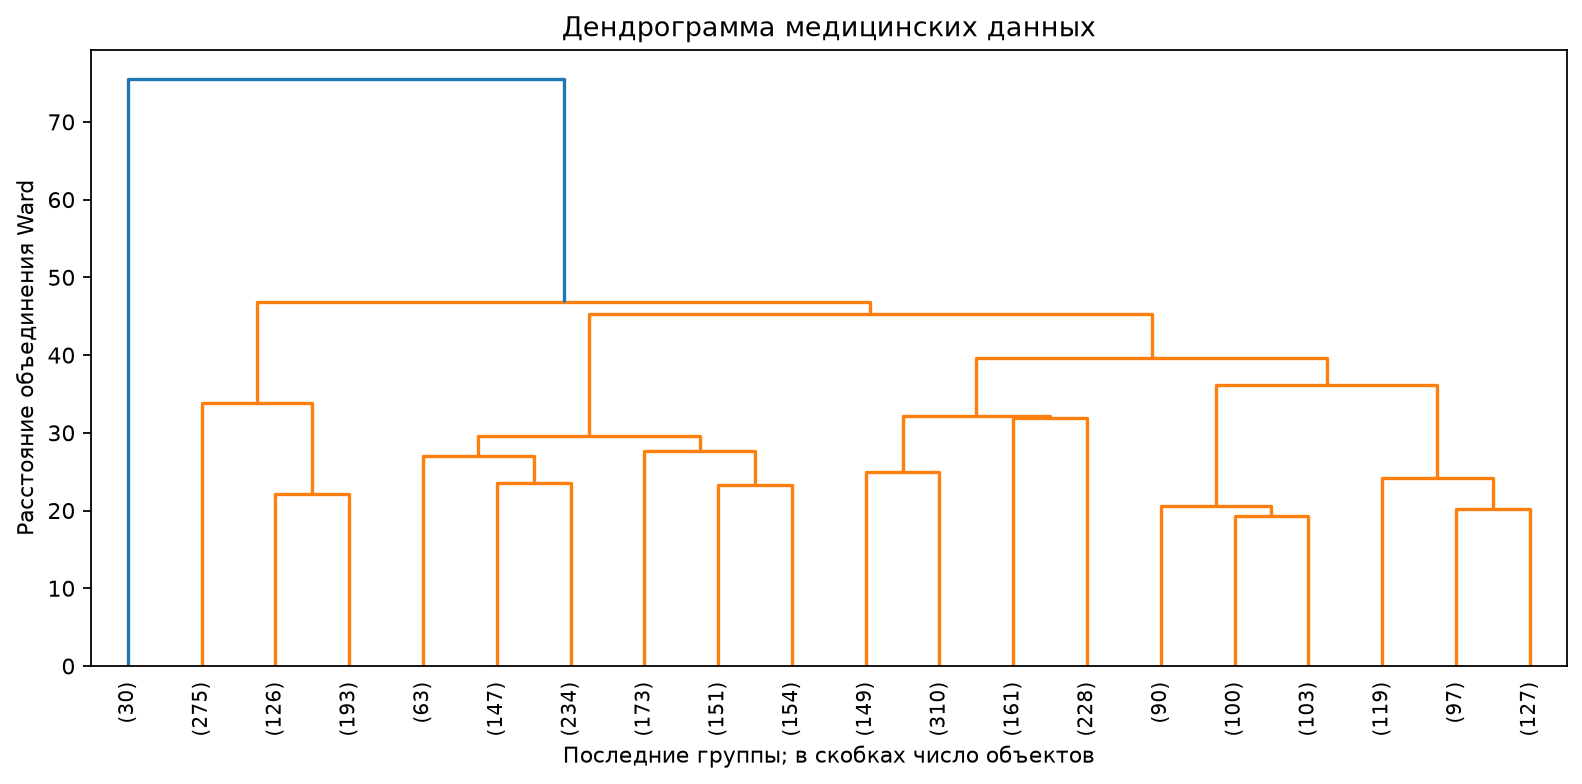

,left,right,distance,count
0,6042.0,6046.0,36.198,636.0
1,6052.0,6054.0,39.687,1484.0
2,6050.0,6055.0,45.237,2406.0
3,6053.0,6056.0,46.890,3000.0
4,6020.0,6057.0,75.525,3030.0


,Disease,cluster
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
...,...,...
3026,0,1
3027,0,1
3028,0,1
3029,0,1


cluster
0    3000
1      30
Name: count, dtype: int64

,age,BMI,systolic_bp,cholesterol_mg_dl,fasting_glucose_mg_dl,symptom_score,CRP_mg_L,WBC_10e9_L
cluster,,,,,,,,
0,53.103,26.479,122.435,199.825,94.399,2.040,1.119,6.818
1,60.633,25.120,120.300,486.840,91.167,2.053,26.742,7.382


silhouette      0.65385
ARI             0.01284
AMI            -0.00139
homogeneity     0.00086
completeness    0.00128
dtype: float64

In [8]:
linked = linkage(X_medical_scaled, method='ward')
plt.figure(figsize=(10, 5))
dendrogram(linked, truncate_mode='lastp', p=20,
           show_leaf_counts=True, leaf_rotation=90, leaf_font_size=9)
plt.xlabel('Последние группы; в скобках число объектов')
plt.ylabel('Расстояние объединения Ward')
plt.title('Дендрограмма медицинских данных')
plt.tight_layout()
plt.show()
display(pd.DataFrame(linked[-5:],
    columns=['left', 'right', 'distance', 'count']).round(3))
hierarchical = AgglomerativeClustering(n_clusters=2, linkage='ward')
labels_hierarchical = hierarchical.fit_predict(X_medical_scaled)
assignments_hierarchical = medical.copy()
assignments_hierarchical['cluster'] = labels_hierarchical
display(assignments_hierarchical[['Disease', 'cluster']])
print('Численность агломеративных кластеров:')
display(assignments_hierarchical.groupby('cluster').size().rename('count'))
means_hierarchical = assignments_hierarchical.groupby('cluster')[X.columns].mean()
display(means_hierarchical.round(3))
metrics_hierarchical = pd.Series({
    'silhouette': silhouette_score(X_medical_scaled, labels_hierarchical),
    'ARI': adjusted_rand_score(y_true, labels_hierarchical),
    'AMI': adjusted_mutual_info_score(y_true, labels_hierarchical),
    'homogeneity': homogeneity_score(y_true, labels_hierarchical),
    'completeness': completeness_score(y_true, labels_hierarchical)})
display(metrics_hierarchical.round(5))

### Результаты Ward и сравнение методов
Ward выделил основную группу из 3000 объектов и малую из 30. В малой группе средний CRP достигает 26,742 мг/л против 1,119 мг/л, холестерин 486,840 мг/дл против 199,825 мг/дл. Таким образом, метод выделил небольшую группу с высокими лабораторными показателями. Это описание наблюдений, а не заключение об их заболеваниях. Номера кластеров разных методов не сопоставляются автоматически.

Для каждого метода сформирован полный DataFrame исходных объектов с меткой `cluster`; исходные индексы сохранены. Принадлежность конкретного объекта определяется по его индексу в выводимых таблицах. 

| Метрика | K-means | Ward |
| --- | --- | --- |
| Силуэт | 0,10682 | 0,65385 |
| ARI | 0,00197 | 0,01284 |
| AMI | 0,00644 | -0,00139 |
| Однородность | 0,03214 | 0,00086 |
| Полнота | 0,00384 | 0,00128 |

Силуэт Ward выше, поскольку найденная малая группа геометрически обособлена в используемом пространстве признаков. При этом внешние метрики обоих методов близки к нулю: найденные разбиения слабо согласуются с `Disease`. Противоречия нет, поскольку силуэт проверяет геометрию, а внешние метрики согласие с исходными классами. Слегка отрицательная AMI возможна из-за поправки на случайность и не означает сбоя расчёта.



## Выводы по работе
На синтетическом наборе из 300 наблюдений кластеризация при `k = 3` дала наибольший силуэт 0,7034; метод локтя согласуется с этим выбором. Стандартизация устранила различие масштабов двух признаков.

В медицинском наборе удалён один дубликат, после чего использованы 3030 объектов и восемь стандартизованных числовых признаков. Пропуски отсутствуют, заполнение не применялось. K-means выделил две слабо разделённые возрастные группы с силуэтом 0,1068. Ward обнаружил группу из 30 наблюдений с высокими CRP и холестерином; его силуэт составил 0,6538. Для выделения этой небольшой группы в данном эксперименте целесообразнее Ward.

Внешние метрики близки к нулю: ARI равен 0,00197 у K-means и 0,01284 у Ward, AMI 0,00644 и -0,00139 соответственно. Следовательно, высокий силуэт Ward не означает восстановления `Disease`. Набор сильно несбалансирован: класс 1 содержит только 49 наблюдений, класс 0 содержит 2981. Результаты характеризуют структуру признаков и не являются диагнозом или проверкой предсказаний для новых пациентов.


# Дополнительные задания

Выполнены задания 3, 4 и 7 методических указаний ЛР4. Используются подготовленные медицинские данные: 3030 объектов и восемь числовых признаков без Disease. Результаты основной части сохранены; дополнительные исследования приведены отдельно.

## Задание 3. Визуализация кластеров

**Задание:** Выполнить визуализацию. Выбрать два признака, построить график scatter, выделить кластеры разными цветами, отметить центры кластеров. Сделать выводы. Повторить ещё для одной пары других признаков.

В ходе выполнения задания были построены диаграммы «Возраст — BMI» и «Холестерин — CRP». Используется уже обученный K-means основной части с k=2. Центры возвращаются из стандартизованных координат в исходные единицы через inverse_transform. На графиках показаны двумерные проекции восьмимерного разбиения; повторное обучение по двум признакам не выполняется. Цвет обозначает кластер, красный крест — проекцию его центра.

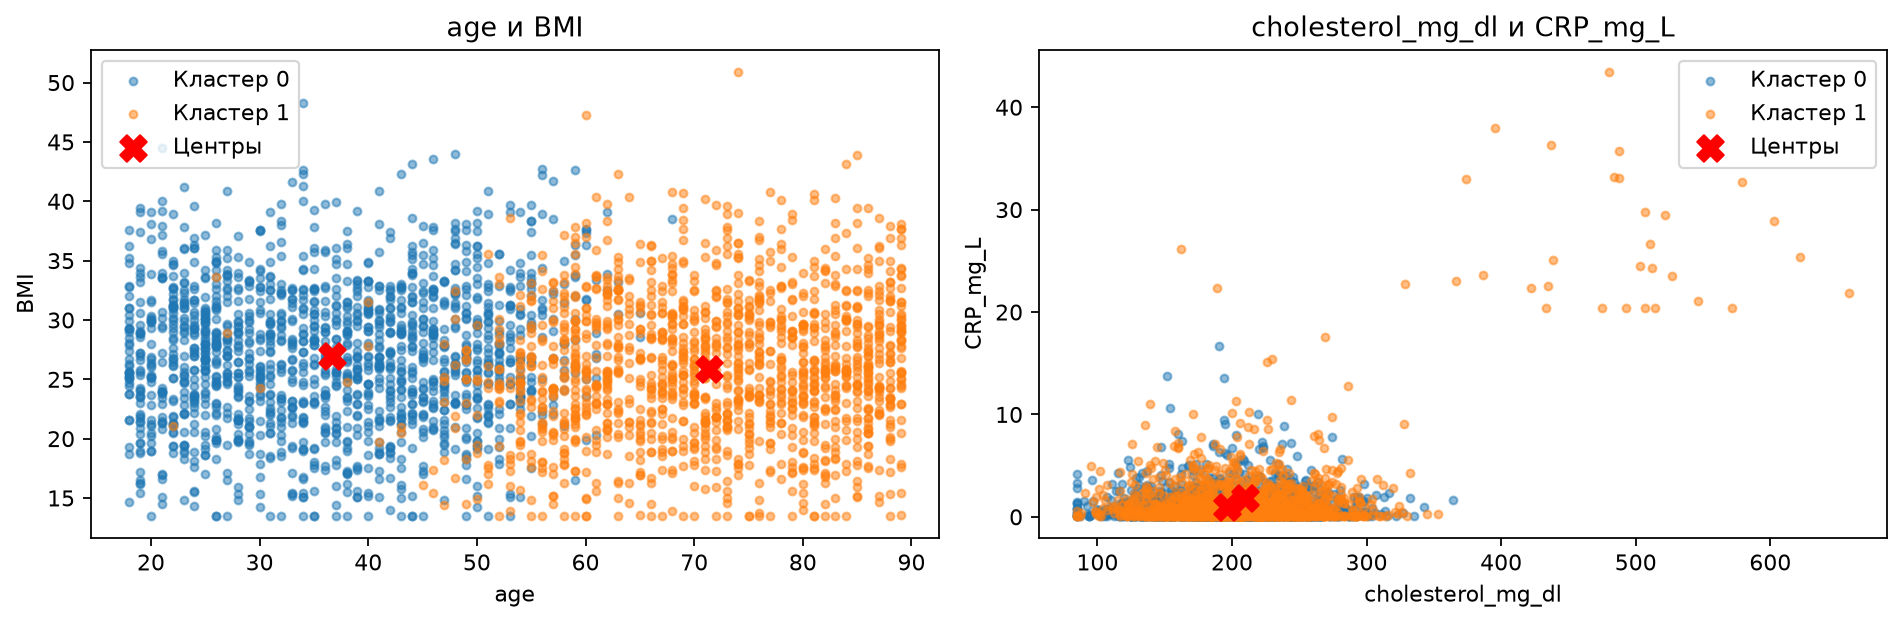

,age,BMI,systolic_bp,cholesterol_mg_dl,fasting_glucose_mg_dl,symptom_score,CRP_mg_L,WBC_10e9_L
0,36.645,26.982,122.628,196.292,92.609,2.155,0.992,6.633
1,71.360,25.897,122.179,209.679,96.301,1.914,1.792,7.033


In [9]:
centers_medical = pd.DataFrame(
    scaler_medical.inverse_transform(kmeans_medical.cluster_centers_),
    columns=X.columns)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, pair in zip(axes, [('age', 'BMI'), ('cholesterol_mg_dl', 'CRP_mg_L')]):
    first, second = pair
    for cluster in range(best_k):
        mask = labels_kmeans == cluster
        ax.scatter(X.loc[mask, first], X.loc[mask, second],
                   s=12, alpha=0.5, label=f'Кластер {cluster}')
    ax.scatter(centers_medical[first], centers_medical[second],
               c='red', marker='X', s=140, label='Центры')
    ax.set(xlabel=first, ylabel=second, title=f'{first} и {second}')
    ax.legend()
plt.tight_layout()
plt.show()
display(centers_medical.round(3))

### Вывод по дополнительному заданию 3

В проекции возраста и BMI группы различаются преимущественно возрастом: средний возраст центров около 36,65 и 71,36 года, BMI около 26,98 и 25,90. В проекции холестерина и CRP группы заметно перекрываются. Их средние холестерины около 196,29 и 209,68 мг/дл, CRP около 0,99 и 1,79 мг/л. Высокие лабораторные показатели не образуют отдельный кластер этой модели K-means. Перекрытие в двумерной проекции не является полным описанием разделения по всем восьми признакам.

## Задание 4. SilhouetteVisualizer и KElbowVisualizer

**Задание:** использовать SilhouetteVisualizer для разного количества кластеров, а также KElbowVisualizer с метрикой silhouette. Сравнить результаты и сделать выводы.

SilhouetteVisualizer показывает силуэт каждого объекта: по горизонтали значение силуэта, по вертикали объекты, сгруппированные по кластерам. Цвета различают группы, ширина полос показывает оценку, их суммарная высота отражает численность. Вертикальная пунктирная линия обозначает средний силуэт.

Были сравнены k=2, 3, 4. KElbowVisualizer проверит k=2-9 с metric='silhouette'. Несмотря на название визуализатора, здесь оценивается силуэт, а не inertia. Для воспроизводимости используются те же n_init=10 и random_state=21, что в основной части. Требуется библиотека yellowbrick. Yellowbrick — библиотека визуальной оценки моделей машинного обучения. Она работает совместно со scikit-learn: группы находит KMeans, а Yellowbrick строит диагностические графики по результатам обучения.

Для Yellowbrick 1.5 с новыми версиями scikit-learn используется force_model=True: отключается только устаревшая проверка типа модели, а обучение и метрики не меняются. Встроенная палитра colors='yellowbrick' позволяет избежать обращения к удалённой в новых версиях matplotlib функции cm.get_cmap.


Выбор KElbowVisualizer: 2


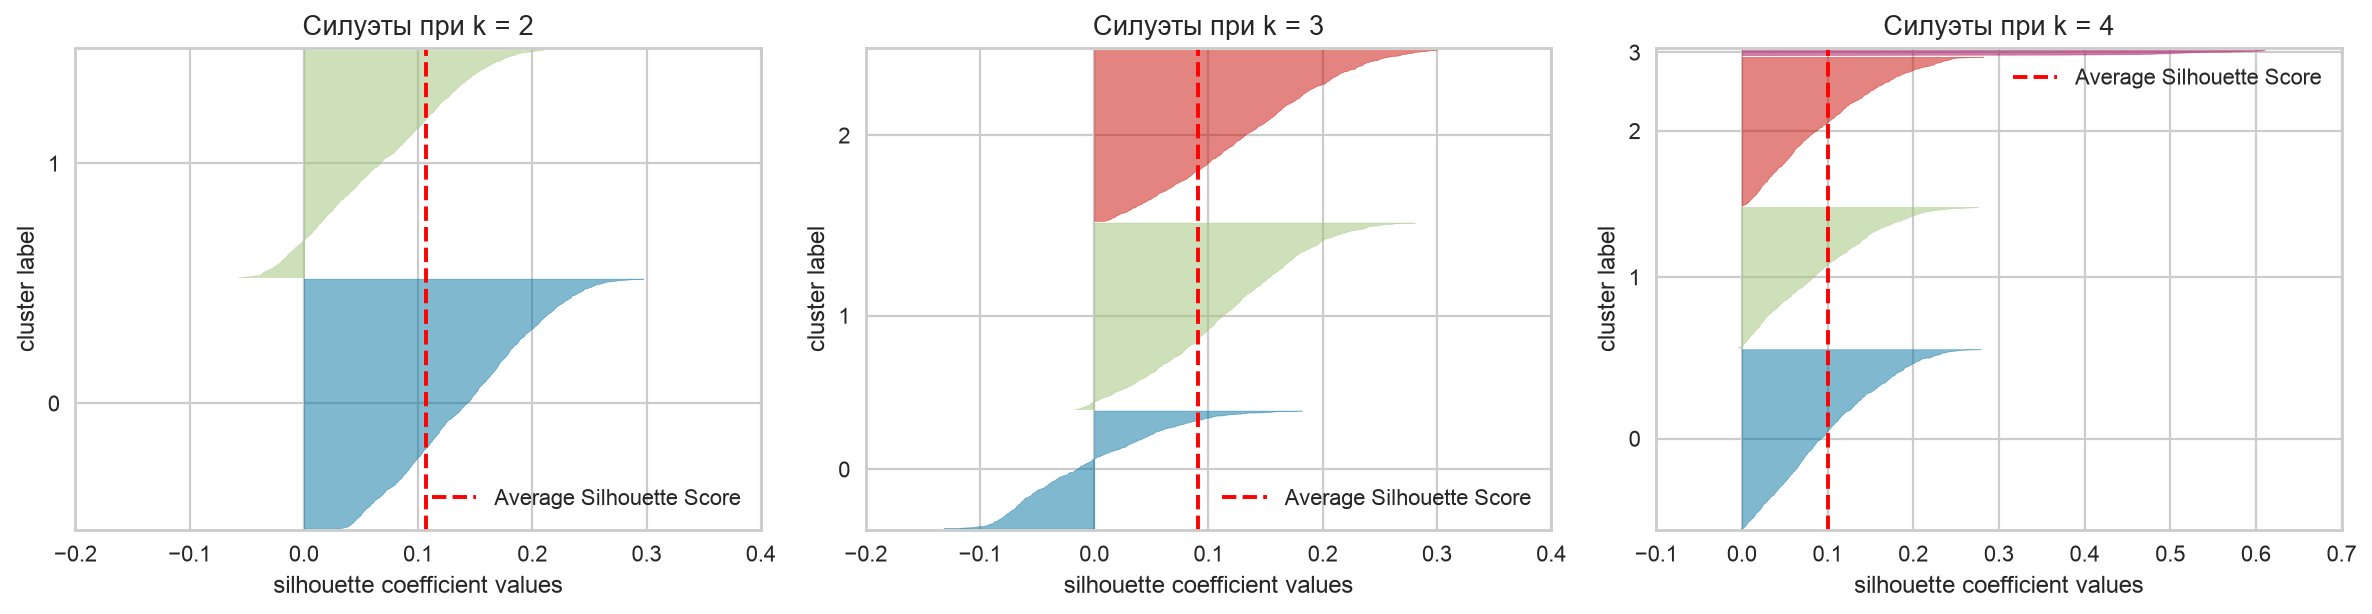

,silhouette
k,
2,0.1068
3,0.0907
4,0.1003


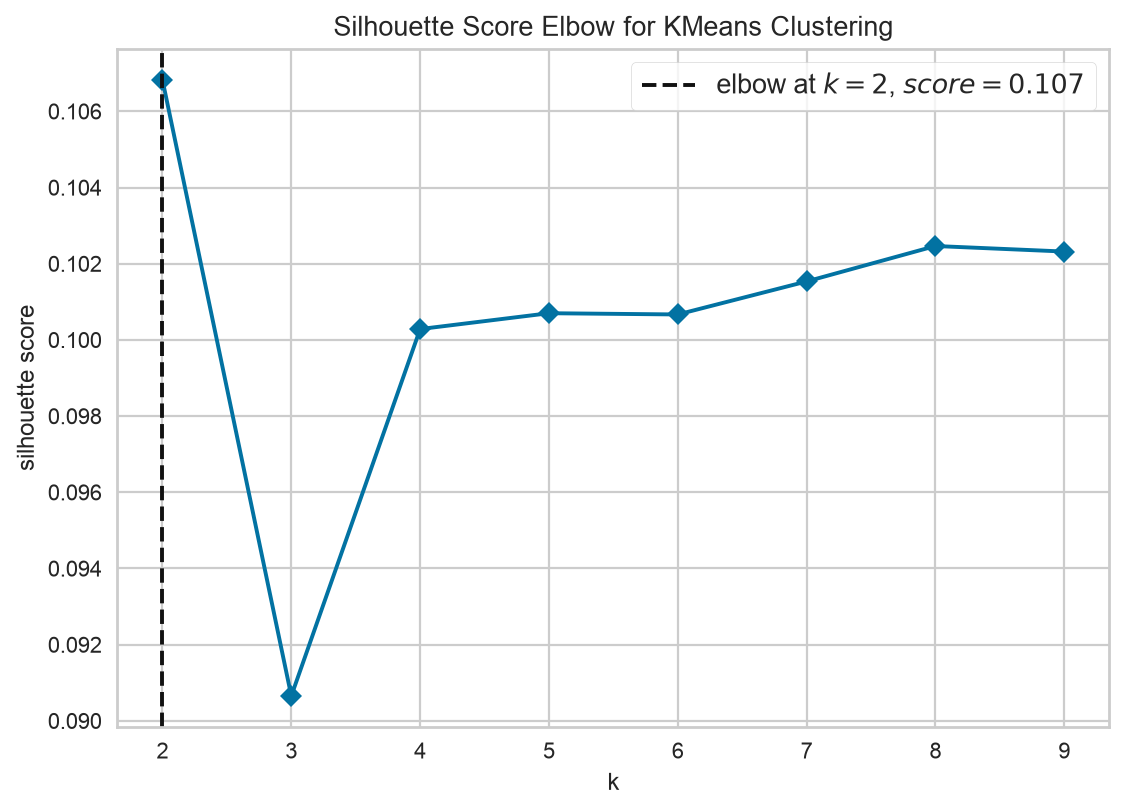

,silhouette
k,
2,0.1068
3,0.0907
4,0.1003
5,0.1007
6,0.1007
7,0.1015
8,0.1025
9,0.1023


In [10]:
from yellowbrick.cluster import SilhouetteVisualizer, KElbowVisualizer

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
silhouette_visual_rows = []
for ax, k in zip(axes, [2, 3, 4]):
    visualizer = SilhouetteVisualizer(
        KMeans(n_clusters=k, n_init=10, random_state=21), ax=ax, colors='yellowbrick', force_model=True)
    visualizer.fit(X_medical_scaled)
    visualizer.finalize()
    ax.set_title(f'Силуэты при k = {k}')
    silhouette_visual_rows.append(
        {'k': k, 'silhouette': visualizer.silhouette_score_})
plt.tight_layout()
plt.show()
display(pd.DataFrame(silhouette_visual_rows).set_index('k').round(4))

elbow_visualizer = KElbowVisualizer(
    KMeans(n_init=10, random_state=21),
    k=list(range(2, 10)), metric='silhouette', timings=False, force_model=True)
elbow_visualizer.fit(X_medical_scaled)
elbow_visualizer.show()
display(pd.DataFrame({'k': elbow_visualizer.k_values_,
                      'silhouette': elbow_visualizer.k_scores_}).set_index('k').round(4))
print('Выбор KElbowVisualizer:', elbow_visualizer.elbow_value_)

### Вывод по дополнительному заданию 4

Средний силуэт при k=2 равен 0,1068, при k=3 — 0,0907, при k=4 — 0,1003. На диаграммах имеются объекты с отрицательными и близкими к нулю значениями: не все наблюдения уверенно относятся к своим группам. При k=3 особенно заметна группа с отрицательными силуэтами. При k=4 выделяется небольшая группа с высокими оценками, но средний силуэт всех объектов остаётся ниже результата при k=2.

KElbowVisualizer с metric='silhouette' отметил k=2. Среди проверенных k=2-9 это также максимум среднего силуэта. Результат согласуется с основной частью. Несмотря на надпись elbow, здесь изображён силуэт, а не inertia; классический метод локтя по сумме квадратов расстояний на этом рисунке не выполняется. Низкий максимум около 0,107 указывает на слабое разделение, а не на идеальное число групп.

## Задание 7. Сравнение способов масштабирования

**Задание:** нормализовать данные с помощью MinMaxScaler и MaxAbsScaler и сравнить полученные итоговые метрики с теми, что были получены на данных, нормализованных с помощью StandardScaler.

StandardScaler вычитает среднее и делит на стандартное отклонение; MinMaxScaler по умолчанию переводит обучающие значения каждого столбца в диапазон [0, 1]; MaxAbsScaler делит на максимальный модуль значения и не вычитает среднее. Эти преобразования по-разному меняют расстояния и влияние экстремальных наблюдений.

Для сопоставимости оставлены одинаковые признаки, объекты и k=2 для обоих методов. У K-means сохранены n_init=10 и random_state=21, у агломеративной модели linkage='ward'. Число кластеров заново не подбирается: исследуется влияние только способа масштабирования. Disease используется лишь после обучения для внешних метрик. Сравниваются все пять метрик основной части.

In [11]:
from sklearn.preprocessing import MinMaxScaler, MaxAbsScaler

scaling_rows = []
for scaler_name, scaler_extra in [
    ('StandardScaler', StandardScaler()),
    ('MinMaxScaler', MinMaxScaler()),
    ('MaxAbsScaler', MaxAbsScaler())]:
    X_extra = scaler_extra.fit_transform(X)
    for method_name, model_extra in [
        ('K-means', KMeans(n_clusters=2, n_init=10, random_state=21)),
        ('Ward', AgglomerativeClustering(n_clusters=2, linkage='ward'))]:
        labels_extra = model_extra.fit_predict(X_extra)
        scaling_rows.append({
            'scaler': scaler_name, 'method': method_name,
            'silhouette': silhouette_score(X_extra, labels_extra),
            'ARI': adjusted_rand_score(y_true, labels_extra),
            'AMI': adjusted_mutual_info_score(y_true, labels_extra),
            'homogeneity': homogeneity_score(y_true, labels_extra),
            'completeness': completeness_score(y_true, labels_extra)})
scaling_comparison = pd.DataFrame(scaling_rows).set_index(['scaler', 'method'])
display(scaling_comparison.round(5))

silhouette      ARI      AMI  homogeneity  completeness
scaler         method                                                          
StandardScaler K-means     0.10682  0.00197  0.00644      0.03214       0.00384
               Ward        0.65385  0.01284 -0.00139      0.00086       0.00128
MinMaxScaler   K-means     0.22050  0.00119  0.00596      0.02991       0.00357
               Ward        0.18413  0.00640  0.00640      0.03144       0.00383
MaxAbsScaler   K-means     0.22412  0.00124  0.00599      0.03005       0.00359
               Ward        0.17371  0.00447  0.00020      0.00285       0.00038

### Вывод по дополнительному заданию 7

При фиксированном k=2 силуэт K-means увеличился с 0,10682 для StandardScaler до 0,22050 для MinMaxScaler и 0,22412 для MaxAbsScaler. При этом ARI остался около 0,0012, AMI около 0,006. Следовательно, более высокая внутренняя оценка не означает хорошего совпадения кластеров с Disease.

У Ward силуэт снизился с 0,65385 для StandardScaler до 0,18413 для MinMaxScaler и 0,17371 для MaxAbsScaler. ARI составил 0,01284; 0,00640; 0,00446 соответственно. AMI для MinMaxScaler равна 0,00640, для MaxAbsScaler — 0,00020; внешние оценки по-прежнему близки к нулю.

Изменение масштаба меняет расстояния, относительное влияние признаков и получаемые группы. В этом эксперименте по силуэту для K-means выше результат MaxAbsScaler, для Ward — StandardScaler. Силуэты рассчитаны в разных преобразованных пространствах, поэтому они не доказывают единственного лучшего способа подготовки. Ни один из трёх способов не привёл к убедительному восстановлению Disease. Вывод ограничен выбранными признаками, k=2 и фиксированными настройками моделей.